# 03 · Modelos
Tarea (a): MLP vs. regresión logística y LightGBM (S1, S8). Tarea (b): LSTM de alerta temprana (S3) vs. baselines. Entrenamiento: `python -m worldsim.train.run_task_a` y `python -m worldsim.train.run_task_b`. Resultados: media ± desviación sobre 5 semillas.

In [1]:
import os, sys
os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd())
sys.path.insert(0, "src")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.options.display.float_format = "{:.4f}".format

## Tarea (a): condiciones iniciales → supervivencia (test, 7 500 planetas)

,Modelo,ROC-AUC,PR-AUC,F1,Brier,ECE,MAE vs P_verdadera (MC)
0,Regresión logística,0.732 ± 0.000,0.709 ± 0.000,0.660 ± 0.000,0.2091 ± 0.0000,0.0177 ± 0.0000,0.3421 ± 0.0000
1,LightGBM,0.966 ± 0.000,0.965 ± 0.000,0.896 ± 0.001,0.0742 ± 0.0005,0.0133 ± 0.0024,0.0772 ± 0.0011
2,MLP,0.973 ± 0.001,0.973 ± 0.001,0.903 ± 0.002,0.0664 ± 0.0008,0.0100 ± 0.0028,0.0540 ± 0.0015


semillas: [2026, 2027, 2028, 2029, 2030] | mejores hiperparámetros MLP: {'hidden': [128, 64], 'dropout': 0.2, 'lr': 0.003, 'weight_decay': 0.0001}
Diferencias pareadas (bootstrap, test, semilla 0):


,Comparación,Δ ROC-AUC [IC 95 %],Δ Brier [IC 95 %]
0,MLP − LightGBM,"+0.0062 [+0.0044, +0.0080]","-0.0066 [-0.0088, -0.0045]"
1,MLP − logística,"+0.2404 [+0.2294, +0.2508]","-0.1422 [-0.1470, -0.1376]"


,hp,val_bce,epochs,sec
11,"{'hidden': [128, 64], 'dropout': 0.2, 'lr': 0....",0.2135,54,6.2842
6,"{'hidden': [128, 64], 'dropout': 0.2, 'lr': 0....",0.2151,138,16.5695
3,"{'hidden': [256, 128], 'dropout': 0.3, 'lr': 0...",0.2181,44,5.3259
2,"{'hidden': [256, 128], 'dropout': 0.1, 'lr': 0...",0.2191,69,8.4877
10,"{'hidden': [256, 128, 64], 'dropout': 0.2, 'lr...",0.2196,135,18.6791


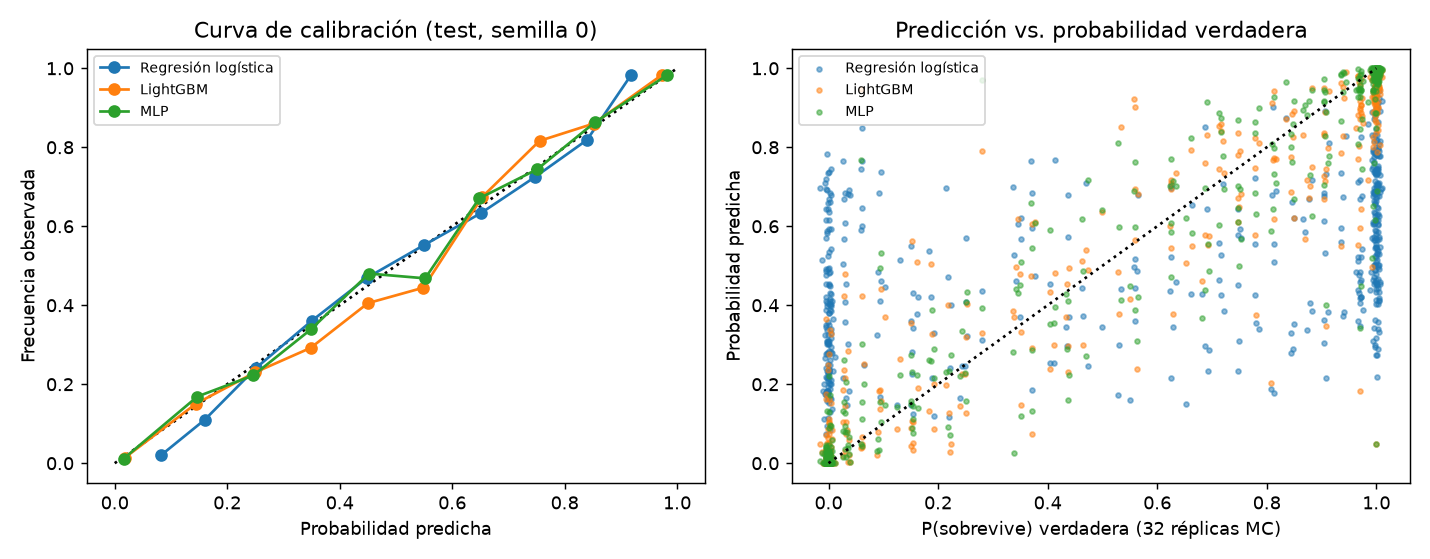

In [2]:
import json
from worldsim.reporting import task_a_tables, task_a_bootstrap, task_b_tables, task_b_bootstrap, lstm_search_table
ta = task_a_tables(); display(ta)
r = json.load(open('outputs/task_a/results.json')); print('semillas:', r['seeds'], '| mejores hiperparámetros MLP:', r['best_hp'])
print('Diferencias pareadas (bootstrap, test, semilla 0):'); display(task_a_bootstrap())
display(pd.DataFrame(r['trials']).sort_values('val_bce').head(5))
display(Image('report/figures/fig_tarea_a_calibracion.png'))

## Tarea (b): primeros k% de la trayectoria → supervivencia
Solo se evalúan planetas aún vivos al final de la ventana; se reporta cuántos quedan fuera.

ROC-AUC


,LSTM (con parámetros),LSTM (sin parámetros),LightGBM (parámetros + resumen),MLP (ventana aplanada),MLP solo parámetros (tarea a)
0%,0.955 ± 0.006,0.572 ± 0.003,0.966 ± 0.000,0.974 ± 0.001,0.973 ± 0.000
5%,0.972 ± 0.001,0.892 ± 0.009,0.965 ± 0.000,0.972 ± 0.001,0.973 ± 0.000
10%,0.973 ± 0.000,0.921 ± 0.009,0.966 ± 0.000,0.970 ± 0.001,0.973 ± 0.000
20%,0.974 ± 0.001,0.937 ± 0.006,0.967 ± 0.000,0.970 ± 0.000,0.972 ± 0.000
40%,0.982 ± 0.000,0.965 ± 0.003,0.978 ± 0.000,0.976 ± 0.001,0.970 ± 0.000
60%,0.987 ± 0.001,0.984 ± 0.001,0.987 ± 0.000,0.984 ± 0.000,0.965 ± 0.000


Brier


,LSTM (con parámetros),LSTM (sin parámetros),LightGBM (parámetros + resumen),MLP (ventana aplanada),MLP solo parámetros (tarea a)
0%,0.0871 ± 0.0076,0.2471 ± 0.0011,0.0736 ± 0.0003,0.0646 ± 0.0015,0.0668 ± 0.0000
5%,0.0679 ± 0.0014,0.1340 ± 0.0056,0.0748 ± 0.0005,0.0668 ± 0.0008,0.0668 ± 0.0000
10%,0.0662 ± 0.0010,0.1142 ± 0.0058,0.0742 ± 0.0003,0.0690 ± 0.0008,0.0668 ± 0.0000
20%,0.0648 ± 0.0009,0.1021 ± 0.0045,0.0736 ± 0.0003,0.0699 ± 0.0006,0.0672 ± 0.0000
40%,0.0544 ± 0.0005,0.0747 ± 0.0030,0.0587 ± 0.0002,0.0619 ± 0.0007,0.0695 ± 0.0000
60%,0.0424 ± 0.0019,0.0470 ± 0.0018,0.0415 ± 0.0006,0.0480 ± 0.0006,0.0735 ± 0.0000


Planetas excluidos (ya colapsados en la ventana)


,Planetas test,Evaluados (vivos),Excluidos,Supervivencia entre vivos
0%,7500,7500,0,0.4901
5%,7500,7500,0,0.4901
10%,7500,7496,4,0.4904
20%,7500,7439,61,0.4942
40%,7500,7140,360,0.5148
60%,7500,5787,1713,0.6352


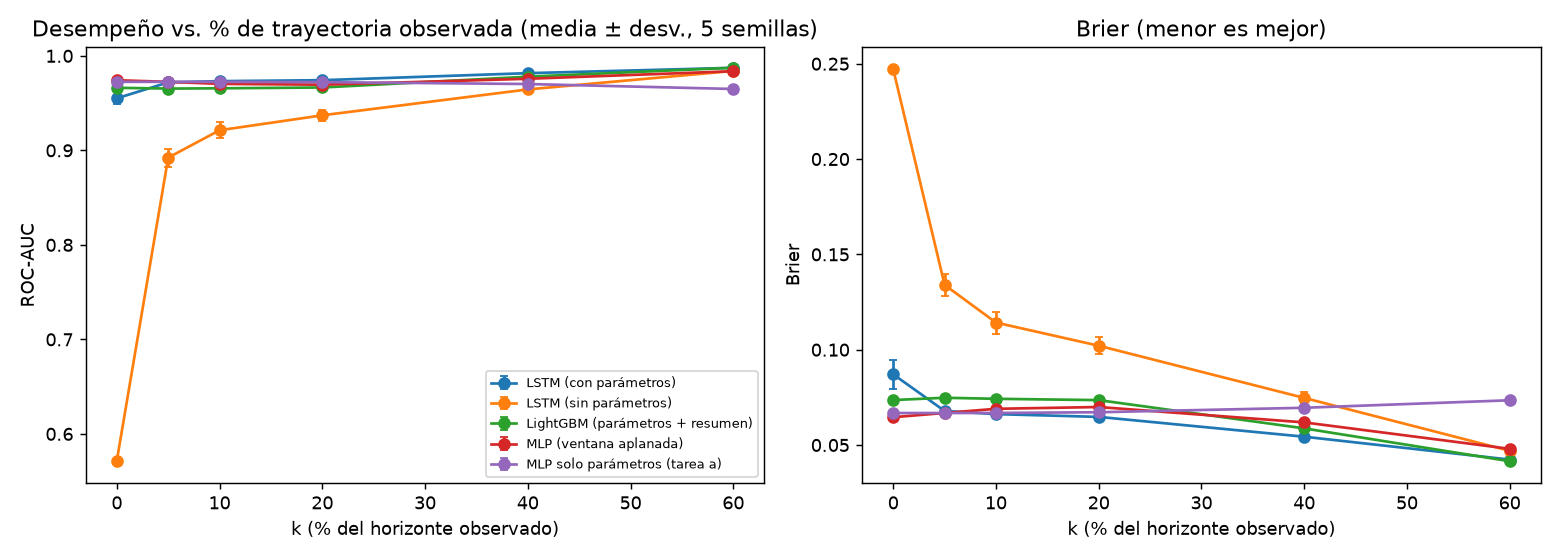

In [3]:
auc, brier, excl = task_b_tables()
print('ROC-AUC'); display(auc); print('Brier'); display(brier); print('Planetas excluidos (ya colapsados en la ventana)'); display(excl)
display(Image('report/figures/fig_tarea_b_curva_k.png'))

### Diferencias pareadas con IC 95 % (bootstrap sobre los planetas de test, semilla 0) y búsqueda de hiperparámetros de la LSTM

In [4]:
display(task_b_bootstrap()); display(lstm_search_table())

,LSTM − LightGBM (resumen),LSTM − MLP solo parámetros,LSTM − LSTM sin parámetros,LSTM − MLP ventana
k,,,,
0%,"-0.0084 [-0.0108, -0.0060]","-0.0147 [-0.0170, -0.0126]","+0.3907 [+0.3766, +0.4040]","-0.0146 [-0.0167, -0.0124]"
5%,"+0.0067 [+0.0046, +0.0088]","+0.0001 [-0.0012, +0.0013]","+0.0850 [+0.0789, +0.0914]","+0.0005 [-0.0009, +0.0018]"
10%,"+0.0078 [+0.0058, +0.0098]","+0.0010 [-0.0004, +0.0024]","+0.0589 [+0.0532, +0.0642]","+0.0028 [+0.0013, +0.0045]"
20%,"+0.0074 [+0.0055, +0.0094]","+0.0018 [+0.0003, +0.0032]","+0.0405 [+0.0366, +0.0448]","+0.0046 [+0.0028, +0.0064]"
40%,"+0.0041 [+0.0022, +0.0061]","+0.0117 [+0.0097, +0.0137]","+0.0200 [+0.0171, +0.0233]","+0.0071 [+0.0051, +0.0092]"
60%,"+0.0003 [-0.0014, +0.0019]","+0.0227 [+0.0196, +0.0260]","+0.0035 [+0.0016, +0.0054]","+0.0034 [+0.0017, +0.0051]"


,hidden,layers,dropout,lr,weight_decay,BCE val,épocas
6,128,2,0.1000,0.0020,0.0100,0.1831,48
1,128,1,0.1000,0.0020,0.0100,0.1866,46
4,64,2,0.2000,0.0030,0.0010,0.1884,38
7,128,1,0.0000,0.0010,0.0010,0.1889,38
0,256,1,0.0000,0.0020,0.0100,0.1892,38
3,64,2,0.1000,0.0010,0.0010,0.1910,40
2,256,2,0.2000,0.0030,0.1000,0.1913,31
5,128,2,0.2000,0.0010,0.0100,0.1939,40
